In [ ]:
"""
Part 1: Load Data
Part 2: Data Quality Assessment
Part 3: Data Cleaning
Part 4: Data Validation → Save Cleaned Data
Part 5: Trade Aggregation
Part 6: Daily & Symbol Reporting
Part 7: Position Reconciliation
Part 8: Data Visualization
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create reports folder
os.makedirs("reports", exist_ok=True)

"""
# Part 1 Load Data
# Load the four datasets and inspect their structure.
# Check data types, convert date columns, and identify invalid dates.
"""

# Load datasets
df_trades = pd.read_csv("data/sample_trades.csv")
df_t0 = pd.read_csv("data/positions_t0.csv")
df_t1 = pd.read_csv("data/positions_t1.csv")
df_corp = pd.read_csv("data/corp_actions.csv")

# Check first few rows of the datasets
print("\nTrades:",df_trades.head())
print("\nPositions T0:",df_t0.head())
print("\nPositions T1:",df_t1.head())
print("\nCorporate Actions:",df_corp.head())

# Check dimension of dataframe
print("\nTrades:", df_trades.shape)
print("Positions T0:", df_t0.shape)
print("Positions T1:", df_t1.shape)
print("Corporate Actions:", df_corp.shape)

# Check data types
print("\nTrade Data types:")
print(df_trades.dtypes)

print("\nPositions T0 data types:")
print(df_t0.dtypes)

print("\nPositions T1 data types:")
print(df_t1.dtypes)

print("\nCorporate Actions data types:")
print(df_corp.dtypes)

# Convert date columns to datetime for accurate date comparisons
df_trades["trade_date"] = pd.to_datetime(
    df_trades["trade_date"], errors="coerce"
)

df_trades["settlement_date"] = pd.to_datetime(
    df_trades["settlement_date"], errors="coerce"
)

df_corp["ex_date"] = pd.to_datetime(
    df_corp["ex_date"], errors="coerce"
)

# Verify date conversion
print("\nDate types after conversion:")
print(df_trades[["trade_date", "settlement_date"]].dtypes)
print(df_corp[["ex_date"]].dtypes)

# Check missing or invalid dates after conversion
print("\nMissing or invalid dates:")
print(df_trades[["trade_date", "settlement_date"]].isna().sum())
print(df_corp[["ex_date"]].isna().sum())


Trades:   trade_id symbol account  trade_date  side  quantity   price   venue  \
0  T100165   AAPL    ACC1  2023-03-01  SELL     -4851  910.53    ARCA   
1  T100145   AAPL    ACC2  2023-03-01   BUY      2548  867.20    BATS   
2  T100164   AAPL    ACC2  2023-03-01  SELL      3604  244.05    ARCA   
3  T100211   AMZN    ACC1  2023-03-01  SELL       351  945.42    NYSE   
4  T100248   AMZN    ACC2  2023-03-01   BUY     -4511  308.28  NASDAQ   

  trade_type  signed_qty    notional      fee settlement_date  
0        MOO       -4851  4416981.03  1798.53      2023-03-02  
1       VWAP        2548  2209625.60   899.73      2023-03-02  
2        REG       -3604   879556.20   358.14      2023-03-02  
3        REG        -351   331842.42   135.12      2023-03-02  
4        MOO        4511  1390651.08   566.25      2023-03-02  

Positions T0:   symbol account  position_t0
0   AAPL    ACC1         8361
1   AAPL    ACC2         5199
2   AAPL    ACC3         4854
3   TSLA    ACC1         8263
4  

In [ ]:
"""
# Part 2 Data Quality Assessment
# Assess data quality before cleaning.
# Summarize missing values and identify suspicious records across trades, positions, and corporate actions.
"""

print("DATA QUALITY ASSESSMENT")
print("----------------------")

print("Total trades:", len(df_trades))

print("\nNull values per column:")
print(df_trades.isna().sum())

# 1) Duplicate trade IDs
duplicate_trades = df_trades[
    df_trades.duplicated(
        subset=["trade_id"],
        keep=False
    )
]

print("\n1. Duplicate trade IDs:")
print("Duplicate rows:", len(duplicate_trades))
print("Duplicate IDs:", duplicate_trades["trade_id"].nunique())
print(duplicate_trades.sort_values("trade_id"))

# 2) Zero quantity trades
zero_qty = df_trades[df_trades["quantity"] == 0]

print("\n2. Zero Quantity Trades")
print("Count:", len(zero_qty))
print(zero_qty)

# 3) Negative quantity trades
negative_qty = df_trades[df_trades["quantity"] < 0]

print("\n3. Negative quantity trades:")
print("Count:", len(negative_qty))
print(negative_qty)

# 4) Missing price
missing_price = df_trades[
    df_trades["price"].isna()
]

print("\n4. Missing price:")
print("Count:", len(missing_price))
print(missing_price)

# 5) Missing venue
missing_venue = df_trades[
    df_trades["venue"].isna()
]

print("\n5. Missing venue:")
print("Count:", len(missing_venue))
print(missing_venue)

# 6) Settlement date issues
bad_settlement = df_trades[
    df_trades["settlement_date"]
    <= df_trades["trade_date"]
]

print("\n6. Settlement date issues:")
print("Count:", len(bad_settlement))
print(bad_settlement)

# 7) Detect price spikes / drops
# unusual 0.01x / 10x / 25x style price changes.
# Use each symbol's median price as a simple reference.
median_price = (
    df_trades
    .groupby("symbol")["price"]
    .transform("median")
)

price_ratio = (
    df_trades["price"]
    / median_price
)

price_outliers = df_trades[
    (price_ratio < 0.1)
    | (price_ratio > 5)
]

# Display price outliers with median and ratio
price_outlier_details = price_outliers[
    ["trade_id", "symbol", "price"]
].copy()

price_outlier_details["median_price"] = median_price.loc[
    price_outliers.index
]

price_outlier_details["price_ratio"] = price_ratio.loc[
    price_outliers.index
]

print("\n7. Possible price spikes/drops:")
print("Count:", len(price_outliers))
print(price_outlier_details)

print("\nNon-positive prices:")
print("Count:", (df_trades["price"] <= 0).sum())

# 8) Check missing position rows
position_check = df_t0.merge(
    df_t1,
    on=["symbol", "account"],
    how="outer",
    indicator=True
)

missing_positions = position_check[
    position_check["_merge"] != "both"
]

print("\n8. Missing position rows:")
print("Count:", len(missing_positions))
print(missing_positions)

# 9) Detect potential bogus position symbols
trade_symbols = set(df_trades["symbol"])

position_symbols = (
    set(df_t0["symbol"]) |
    set(df_t1["symbol"])
)

bogus_symbols = position_symbols - trade_symbols

print("\n9. Potential bogus position symbols:")
print("Count:", len(bogus_symbols))
print(bogus_symbols)

# 9-1) Check account-symbol combinations without trades
trade_accounts = set(
    zip(df_trades["account"], df_trades["symbol"])
)

position_accounts = (
    set(zip(df_t0["account"], df_t0["symbol"])) |
    set(zip(df_t1["account"], df_t1["symbol"]))
)

no_trade_accounts = position_accounts - trade_accounts

print("\n9-1. Account-symbol combinations without trades:")
print(no_trade_accounts)

# 10) Check missing corporate action shares
missing_corp_shares = df_corp[
    df_corp["corp_shares"].isna()
]

print("\n10. Missing corporate action shares:")
print("Count:", len(missing_corp_shares))
print(missing_corp_shares)

# 11) Check trade symbols not listed in corporate actions
corp_symbols = set(df_corp["symbol"])

symbols_without_corp = trade_symbols - corp_symbols

print("\n11. Trade symbols without corporate action records:")
print("Count:", len(symbols_without_corp))
print(symbols_without_corp)

# 12) Corporate action rows marked NONE
# but still containing shares
corp_none_with_shares = df_corp[
    (df_corp["corp_type"] == "NONE")
    & (df_corp["corp_shares"].notna())
    & (df_corp["corp_shares"] != 0)
]

print("\n12. NONE corporate actions with non-zero shares:")
print("Count:", len(corp_none_with_shares))
print(corp_none_with_shares)

DATA QUALITY ASSESSMENT
----------------------
Total trades: 286

Null values per column:
trade_id           0
symbol             0
account            0
trade_date         0
side               0
quantity           0
price              4
venue              4
trade_type         0
signed_qty         0
notional           4
fee                0
settlement_date    0
dtype: int64

1. Duplicate trade IDs:
Duplicate rows: 16
Duplicate IDs: 8
    trade_id symbol account trade_date  side  quantity     price   venue  \
99   T100000   META    ACC2 2023-03-04  SELL      3729  696.7500    BATS   
101  T100000   META    ACC2 2023-03-04  SELL      3772    6.9634    BATS   
229  T100012  GOOGL    ACC2 2023-03-09   BUY      4116  699.3100    BATS   
232  T100012  GOOGL    ACC2 2023-03-09   BUY      4084  705.6100     NaN   
187  T100017  GOOGL    ACC1 2023-03-07  SELL      4817  999.3700  NASDAQ   
188  T100017  GOOGL    ACC1 2023-03-07  SELL      4836  984.2800  NASDAQ   
238  T100180   META    ACC3 202

In [ ]:
"""
# Part 3 Clean Data

# Clean trade data while preserving the original dataset.
# Remove invalid and duplicate trades, then recalculate signed quantities and notional values.
# 1) Remove duplicate trade IDs
# 2) Remove zero quantity trades
# 3) Remove negative quantity trades
# 4) Remove missing price
# 5) Remove missing venue
# 6) Remove invalid settlement dates
# 7) Recalculate signed_qty and notional
# 8) Flag price outliers
# 9) Remove identified bogus position symbols
# 10) Exclude incomplete account-symbol pairs from reconciliation
"""

# Create a copy before cleaning
df_clean = df_trades.copy()

print("CLEANING PROCESS")
print("----------------------")
print("Starting rows:", len(df_clean))

# 1) Remove duplicate trade IDs
before = len(df_clean)

df_clean.drop_duplicates(
    subset=["trade_id"],
    keep="first",
    inplace=True
)

print("\n1. Duplicate trade IDs")
print("Rows deleted:", before - len(df_clean))
print("Rows left:",len(df_clean))

# 2) Remove zero quantity trades
before = len(df_clean)

df_clean = df_clean[df_clean["quantity"] != 0]

print("\n2. Zero quantity trades")
print("Rows deleted:",before - len(df_clean))
print("Rows left:",len(df_clean))

# 3) Remove negative quantity trades
before = len(df_clean)

df_clean = df_clean[df_clean["quantity"] > 0]

print("\n3. Negative Quantity Trades")
print("Rows deleted:", before - len(df_clean))
print("Rows left:", len(df_clean))

# 4) Remove rows with missing price
before = len(df_clean)

df_clean = df_clean[df_clean["price"].notna()]

print("\n4. Missing price")
print("Rows deleted:",before - len(df_clean))
print("Rows left:",len(df_clean))

#  5) Remove rows with missing venue
before = len(df_clean)

df_clean = df_clean[df_clean["venue"].notna()]

print("\n5. Missing venue")
print("Rows deleted:",before - len(df_clean))
print("Rows left:",len(df_clean))

# 6)Remove invalid settlement dates
before = len(df_clean)

df_clean = df_clean[
    df_clean["settlement_date"]
    > df_clean["trade_date"]
]

print("\n6. Settlement date issues")
print("Rows deleted:",before - len(df_clean))
print("Rows left:",len(df_clean))

# 7) Calculate signed quantity and notional
# Assign positive quantities to BUY and negative quantities to SELL.
# Calculate the total value of each trade.

# np.where(condition, value_if_true, value_if_false)
df_clean["signed_qty"] = np.where(
    df_clean["side"] == "BUY",
    df_clean["quantity"],
    -df_clean["quantity"]
)

# Recalculate notional
df_clean["notional"] = (
    df_clean["quantity"]
    * df_clean["price"]
)

print("\nRecalculated signed quantity and notional:")

print(
    df_clean[
        [
            "trade_id",
            "symbol",
            "side",
            "quantity",
            "signed_qty",
            "price",
            "notional"
        ]
    ].head(10)
)

# 8) Flag potential price outliers after cleaning
# Use each symbol's median price as a reference
median_price = (
    df_clean.groupby("symbol")["price"].transform("median")
)

price_ratio = df_clean["price"] / median_price

# Flag outliers without removing trades
df_clean["price_outlier_flag"] = (
    (price_ratio < 0.1)
    | (price_ratio > 5)
)

price_outliers_clean = df_clean[
    df_clean["price_outlier_flag"]
]

print("\n8. Potential price outliers after cleaning:")
print("Count:", len(price_outliers_clean))
print(
    price_outliers_clean[
        ["trade_id", "symbol", "account", "price", "price_outlier_flag"]
    ]
)

# 9) Remove identified bogus position symbols
df_t0_clean = df_t0[
    ~df_t0["symbol"].isin(bogus_symbols)
].copy()

df_t1_clean = df_t1[
    ~df_t1["symbol"].isin(bogus_symbols)
].copy()

print("\n9. BOGUS POSITION SYMBOL CLEANING")
print("Removed symbols:", bogus_symbols)
print("T0 rows removed:", len(df_t0) - len(df_t0_clean))
print("T1 rows removed:", len(df_t1) - len(df_t1_clean))

# 10) Exclude account-symbol pairs with missing positions
missing_pairs = missing_positions[
    ["account", "symbol"]
].drop_duplicates()

df_t0_clean = df_t0_clean.merge(
    missing_pairs,
    on=["account", "symbol"],
    how="left",
    indicator=True
)

df_t0_clean = (
    df_t0_clean[df_t0_clean["_merge"] == "left_only"]
    .drop(columns="_merge")
    .copy()
)

print("\n10. MISSING POSITION CLEANING")
print("Excluded account-symbol pairs:")
print(missing_pairs)

# Final cleaning summary
print("\nCLEANING RESULT")
print("----------------------")

print("Trades before cleaning:", len(df_trades))
print("Trades after cleaning:", len(df_clean))
print("Trades removed:", len(df_trades) - len(df_clean))

print("\nPositions T0 before:", len(df_t0))
print("Positions T0 after:", len(df_t0_clean))

print("\nPositions T1 before:", len(df_t1))
print("Positions T1 after:", len(df_t1_clean))

CLEANING PROCESS
----------------------
Starting rows: 286

1. Duplicate trade IDs
Rows deleted: 8
Rows left: 278

2. Zero quantity trades
Rows deleted: 6
Rows left: 272

3. Negative Quantity Trades
Rows deleted: 6
Rows left: 266

4. Missing price
Rows deleted: 4
Rows left: 262

5. Missing venue
Rows deleted: 3
Rows left: 259

6. Settlement date issues
Rows deleted: 6
Rows left: 253

Recalculated signed quantity and notional:
   trade_id symbol  side  quantity  signed_qty   price    notional
1   T100145   AAPL   BUY      2548        2548  867.20  2209625.60
2   T100164   AAPL  SELL      3604       -3604  244.05   879556.20
3   T100211   AMZN  SELL       351        -351  945.42   331842.42
5   T100066   AMZN  SELL      2132       -2132  532.07  1134373.24
6   T100243  GOOGL  SELL      1343       -1343  170.58   229088.94
7   T100161  GOOGL  SELL      4187       -4187  881.49  3690798.63
8   T100085  GOOGL  SELL      2213       -2213  886.51  1961846.63
9   T100063    JPM  SELL       584

In [ ]:
"""
# Part 4 Data Validation
# Validate the cleaned dataset for duplicates, missing values, and invalid records.
# Verify signed quantities and notional calculations before saving the cleaned data.
"""
print("\nPART 4: DATA VALIDATION")
print("----------------------")

# 1) Check remaining duplicate trade IDs
duplicate_ids = df_clean[
    df_clean.duplicated(subset=["trade_id"], keep=False)
]

print("\n1. Remaining Duplicate Trade IDs")
print("Count:", len(duplicate_ids))

# 2) Check invalid quantities
print("\n2. Invalid Quantities")
print("Count:", len(df_clean[df_clean["quantity"] <= 0]))

# 3) Check missing prices
print("\n3. Missing Prices")
print("Count:", df_clean["price"].isna().sum())

# 4) Check missing venues
print("\n4. Missing Venues")
print("Count:", df_clean["venue"].isna().sum())

# 5) Check invalid settlement dates
invalid_settlement = df_clean[
    df_clean["settlement_date"] <= df_clean["trade_date"]
]

print("\n5. Invalid Settlement Dates")
print("Count:", len(invalid_settlement))

# 6) Check signed quantity
invalid_signed_qty = df_clean[
    (~df_clean["side"].isin(["BUY", "SELL"])) |
    ((df_clean["side"] == "BUY") & (df_clean["signed_qty"] != df_clean["quantity"])) |
    ((df_clean["side"] == "SELL") & (df_clean["signed_qty"] != -df_clean["quantity"]))
]

print("\n6. Invalid Signed Quantities")
print("Count:", len(invalid_signed_qty))

# 7) Check notional calculation
invalid_notional = df_clean[
    ~np.isclose(
        df_clean["notional"],
        df_clean["quantity"] * df_clean["price"]
    )
]

print("\n7. Invalid Notional Calculations")
print("Count:", len(invalid_notional))

# 8) Check flagged price outliers
print("\n8. Flagged Price Outliers")
print("Count:", df_clean["price_outlier_flag"].sum())

# Validation summary
print("\nVALIDATION RESULT")
print("----------------------")

validation_issues = (
    len(duplicate_ids)
    + len(df_clean[df_clean["quantity"] <= 0])
    + df_clean["price"].isna().sum()
    + df_clean["venue"].isna().sum()
    + len(invalid_settlement)
    + len(invalid_signed_qty)
    + len(invalid_notional)
)

print("Rows validated:", len(df_clean))
print("Total validation issues:", validation_issues)
print("Validation passed:", validation_issues == 0)

"""
# Save Cleaned Trades
"""
if validation_issues == 0:
    df_clean.to_csv("reports/cleaned_trades.csv", index=False)
    print("\nCleaned trades saved successfully.")
else:
    print("\nValidation failed. Cleaned trades not saved.")


PART 4: DATA VALIDATION
----------------------

1. Remaining Duplicate Trade IDs
Count: 0

2. Invalid Quantities
Count: 0

3. Missing Prices
Count: 0

4. Missing Venues
Count: 0

5. Invalid Settlement Dates
Count: 0

6. Invalid Signed Quantities
Count: 0

7. Invalid Notional Calculations
Count: 0

8. Flagged Price Outliers
Count: 15

VALIDATION RESULT
----------------------
Rows validated: 253
Total validation issues: 0
Validation passed: True

Cleaned trades saved successfully.


In [ ]:
"""
# Part 5 Trade Aggregation
# Aggregate cleaned trades by symbol and account to calculate net trading quantities.
# Validate aggregated results against the total signed quantity.
"""
print("\nPART 5: TRADE AGGREGATION")
print("----------------------")

# 1) Calculate net quantity by symbol
df_net_trades = (
    df_clean.groupby("symbol", as_index=False)["signed_qty"]
    .sum()
    .rename(columns={"signed_qty": "net_qty"})
)

print("\n1. Net Trading Quantity by Symbol")
print(df_net_trades)

# 2) Calculate net quantity by account and symbol
df_account_net = (
    df_clean.groupby(["account", "symbol"], as_index=False)["signed_qty"]
    .sum()
    .rename(columns={"signed_qty": "net_qty"})
)

print("\n2. Net Trading Quantity by Account and Symbol")
print(df_account_net)

# 3) Validate aggregation
print("\n3. Aggregation Validation")

total_signed_qty = df_clean["signed_qty"].sum()
total_symbol_qty = df_net_trades["net_qty"].sum()
total_account_qty = df_account_net["net_qty"].sum()

print("Total signed quantity:", total_signed_qty)
print("Total net quantity by symbol:", total_symbol_qty)
print("Total net quantity by account and symbol:", total_account_qty)

print(
    "Aggregation matched:",
    np.isclose(total_signed_qty, total_symbol_qty)
    and np.isclose(total_signed_qty, total_account_qty)
)

# 4) Aggregate trades for reconciliation
# Include only account-symbol pairs with complete positions

valid_pairs = df_t0_clean[
    ["account", "symbol"]
]

df_recon_trades = df_clean.merge(
    valid_pairs,
    on=["account", "symbol"],
    how="inner"
)

df_recon_net = (
    df_recon_trades
    .groupby("symbol", as_index=False)["signed_qty"]
    .sum()
    .rename(columns={"signed_qty": "net_qty"})
)

print("\n4. RECONCILIATION TRADE AGGREGATION")
print(df_recon_net)
print("Reconciliation trade rows:", len(df_recon_trades))
print(
    "Reconciliation aggregation matched:",
    df_recon_trades["signed_qty"].sum() == df_recon_net["net_qty"].sum()
)


PART 5: TRADE AGGREGATION
----------------------

1. Net Trading Quantity by Symbol
  symbol  net_qty
0   AAPL    11329
1   AMZN     5861
2  GOOGL      666
3    JPM     -127
4   META    31813
5   MSFT    -8691
6   NVDA     -928
7    SPY      577
8   TSLA    -7390
9    XOM    -7177

2. Net Trading Quantity by Account and Symbol
   account symbol  net_qty
0     ACC1   AAPL     4429
1     ACC1   AMZN    -1522
2     ACC1  GOOGL      355
3     ACC1    JPM     2277
4     ACC1   META      156
5     ACC1   MSFT    -9896
6     ACC1   NVDA     4012
7     ACC1    SPY   -14749
8     ACC1   TSLA    -2627
9     ACC1    XOM     5917
10    ACC2   AAPL     5968
11    ACC2   AMZN    -1112
12    ACC2  GOOGL     2380
13    ACC2    JPM    -3175
14    ACC2   META     9509
15    ACC2   MSFT     1382
16    ACC2   NVDA    -1486
17    ACC2    SPY     5584
18    ACC2   TSLA    -3767
19    ACC2    XOM    -7754
20    ACC3   AAPL      932
21    ACC3   AMZN     8495
22    ACC3  GOOGL    -2069
23    ACC3    JPM     

In [ ]:
"""
# Part 6: Daily & Symbol Reporting

# Generate daily and symbol-level trading summaries.
# Calculate trade counts, quantities, notional values, and average prices.
# Validate reporting results and export reports as CSV files.
"""
print("\nPART 6: DAILY & SYMBOL REPORTING")
print("----------------------")

# 1) Daily summary by date and symbol
daily_report = (
    df_clean
    .groupby(["trade_date", "symbol"])
    .agg(
        trade_count=("trade_id", "count"),
        total_quantity=("quantity", "sum"),
        net_qty=("signed_qty", "sum"),
        total_notional=("notional", "sum"),
        avg_price=("price", "mean")
    )
    .reset_index()
    .sort_values(["trade_date", "symbol"])
)

print("\n1. DAILY REPORT")
print(daily_report.head(10))


# 2) Summary by symbol
symbol_report = (
    df_clean
    .groupby("symbol")
    .agg(
        trade_count=("trade_id", "count"),
        total_quantity=("quantity", "sum"),
        net_qty=("signed_qty", "sum"),
        total_notional=("notional", "sum"),
        avg_price=("price", "mean")
    )
    .reset_index()
    .sort_values("total_quantity", ascending=False)
)

print("\n2. SYMBOL REPORT")
print(symbol_report)


# 3) Validate reporting results
print("\n3. REPORTING VALIDATION")
print("----------------------")

daily_matched = (
    daily_report["net_qty"].sum()
    == df_clean["signed_qty"].sum()
)

symbol_matched = (
    symbol_report["net_qty"].sum()
    == df_clean["signed_qty"].sum()
)

print("Daily report net quantity matched:", daily_matched)
print("Symbol report net quantity matched:", symbol_matched)

print("Daily report rows:", len(daily_report))
print("Symbol report rows:", len(symbol_report))


PART 6: DAILY & SYMBOL REPORTING
----------------------

1. DAILY REPORT
  trade_date symbol  trade_count  total_quantity  net_qty  total_notional  \
0 2023-03-01   AAPL            2            6152    -1056      3089181.80   
1 2023-03-01   AMZN            2            2483    -2483      1466215.66   
2 2023-03-01  GOOGL            3            7743    -7743      5881734.20   
3 2023-03-01    JPM            3            7337     6169      5930991.92   
4 2023-03-01   META            1            3472     3472      2436649.60   
5 2023-03-01   MSFT            3            8031    -7357      4774849.96   
6 2023-03-01   NVDA            5           14837     1399      7071638.67   
7 2023-03-01    SPY            1            3190     3190      1457957.60   
8 2023-03-01   TSLA            3            6896    -6896      4406985.56   
9 2023-03-01    XOM            4           11568    -3500      7316763.70   

    avg_price  
0  555.625000  
1  738.745000  
2  646.193333  
3  697.920000 

In [ ]:
# 4) Save reports after validation
print("\n4. SAVE REPORTS")
print("----------------------")

if daily_matched and symbol_matched:
    daily_report.to_csv(
        "reports/daily_report.csv",
        index=False
    )

    symbol_report.to_csv(
        "reports/symbol_report.csv",
        index=False
    )

    print("Daily and symbol reports saved successfully.")
else:
    print("Reporting validation failed. Reports not saved.")


4. SAVE REPORTS
----------------------
Daily and symbol reports saved successfully.


In [ ]:
"""
# Part 7: Position Reconciliation

# Compare position changes against net trades and corporate actions.
# Identify mismatches and missing data at the symbol level.
# Record account-level position exclusions from cleaning.
# Export the reconciliation report.
"""
print("\nPART 7: POSITION RECONCILIATION")
print("----------------------")

# 1) Aggregate T0 positions by symbol
positions_t0 = (
    df_t0_clean.groupby("symbol", as_index=False)["position_t0"].sum()
)

# 2) Aggregate T1 positions by symbol
positions_t1 = (
    df_t1_clean
    .groupby("symbol", as_index=False)["position_t1"].sum()
)

print("\n1. POSITIONS T0")
print(positions_t0)

print("\n2. POSITIONS T1")
print(positions_t1)

# 3) Merge T0 and T1 positions
recon = positions_t0.merge(
    positions_t1,
    on="symbol",
    how="outer",
    indicator=True
)

print("\n3. POSITIONS AFTER MERGE")
print(recon)

# Check missing position records
print("\nPosition Merge Status")
print(recon["_merge"].value_counts())

# 4) Merge reconciliation net trades
recon = recon.merge(
    df_recon_net,
    on="symbol",
    how="left"
)

# Flag symbols without trading activity
recon["no_trades"] = recon["net_qty"].isna()

print("\n4. POSITIONS WITH NET TRADES")
print(recon)

print("\nSymbols without trading activity:")
print(recon.loc[recon["no_trades"], ["symbol", "net_qty"]])

# 5) Fill missing net quantities
recon["net_qty"] = recon["net_qty"].fillna(0)

print("\n5. NET TRADES AFTER FILL")
print(recon[["symbol", "net_qty", "no_trades"]])

# 6) Merge corporate actions
recon = recon.merge(
    df_corp[
        ["symbol", "corp_shares"]
    ],
    on="symbol",
    how="left"
)

print("\n6. POSITIONS WITH CORPORATE ACTIONS")
print(recon[["symbol", "net_qty", "corp_shares"]])

# 7) Flag missing corporate action data
# Distinguish missing records from missing share values
recon["corp_record_missing"] = ~recon["symbol"].isin(
    df_corp["symbol"]
)

recon["corp_action_missing"] = (
    recon["corp_shares"].isna()
    & ~recon["corp_record_missing"]
)

print("\n7. MISSING CORPORATE ACTION DATA")
print(
    recon.loc[
        recon["corp_action_missing"] | recon["corp_record_missing"],
        ["symbol", "corp_shares",
         "corp_record_missing", "corp_action_missing"]
    ]
)

# 8)  Fill zero only when no corporate action record exists
recon.loc[
    recon["corp_record_missing"],
    "corp_shares"
] = 0

print("\n8. CORPORATE ACTIONS AFTER HANDLING MISSING VALUES")
print(
    recon[
        ["symbol", "corp_shares",
         "corp_record_missing", "corp_action_missing"]
    ]
)

# 9) Calculate position changes
recon["delta_pos"] = (
    recon["position_t1"] - recon["position_t0"]
)

# 10) Calculate expected position changes
recon["expected_delta"] = (
    recon["net_qty"] + recon["corp_shares"]
)

# 11) Calculate reconciliation differences
recon["recon_diff"] = (
    recon["delta_pos"] - recon["expected_delta"]
)

# 12) Flag symbols with excluded missing positions
recon["excluded_missing_position"] = recon["symbol"].isin(
    missing_pairs["symbol"]
)

print("\n12. EXCLUDED MISSING POSITIONS")
print(missing_pairs)

# 13) Assign reconciliation status
recon["status"] = "MISMATCH"

recon.loc[
    recon["recon_diff"] == 0,
    "status"
] = "MATCH"

# Flag invalid reconciliation records
invalid_condition = (
    recon["position_t0"].isna()
    | recon["position_t1"].isna()
    | recon["corp_action_missing"]
)

recon.loc[
    invalid_condition,
    "status"
] = "INVALID"

print("\nRECONCILIATION RESULTS")
print("----------------------")
print(recon[[
    "symbol",
    "delta_pos",
    "net_qty",
    "corp_shares",
    "expected_delta",
    "recon_diff",
    "status"
]])

print("\nReconciliation status count:")
print(recon["status"].value_counts())

# 14) Validate reconciliation results
print("\n14. RECONCILIATION VALIDATION")

print("Total symbols:", len(recon))
print("Duplicate symbols:", recon["symbol"].duplicated().sum())
print("Missing status:", recon["status"].isna().sum())

print(
    "All statuses valid:",
    recon["status"].isin(
        ["MATCH", "MISMATCH", "INVALID"]
    ).all()
)


PART 7: POSITION RECONCILIATION
----------------------

1. POSITIONS T0
  symbol  position_t0
0   AAPL        18414
1   AMZN         8833
2  GOOGL        14160
3    JPM        18553
4   META         8193
5   MSFT         9693
6   NVDA         6644
7    SPY        14737
8   TSLA        19542
9    XOM         7307

2. POSITIONS T1
  symbol  position_t1
0   AAPL        26181
1   AMZN        19205
2  GOOGL         9149
3    JPM        14619
4   META        45583
5   MSFT         1002
6   NVDA        14667
7    SPY        15564
8   TSLA        16950
9    XOM       -12424

3. POSITIONS AFTER MERGE
  symbol  position_t0  position_t1 _merge
0   AAPL        18414        26181   both
1   AMZN         8833        19205   both
2  GOOGL        14160         9149   both
3    JPM        18553        14619   both
4   META         8193        45583   both
5   MSFT         9693         1002   both
6   NVDA         6644        14667   both
7    SPY        14737        15564   both
8   TSLA        19542 

In [ ]:
"""
# Save reconciliation reports
"""
recon.to_csv(
    "reports/full_reconciliation.csv",
    index=False
)


print("Reconciliation reports saved successfully.")

Reconciliation reports saved successfully.



PART 8: DATA VISUALIZATION
----------------------


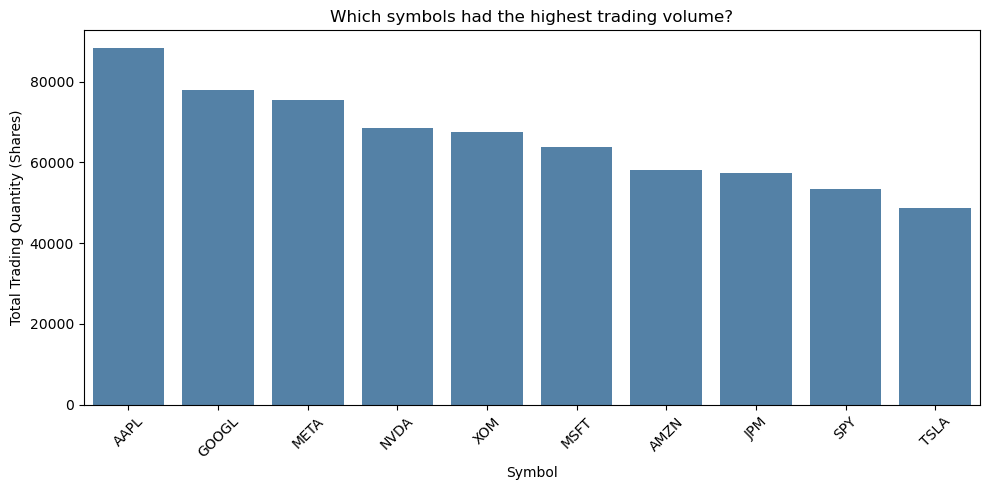

Insight: AAPL had the highest trading volume, followed by GOOGL and META.


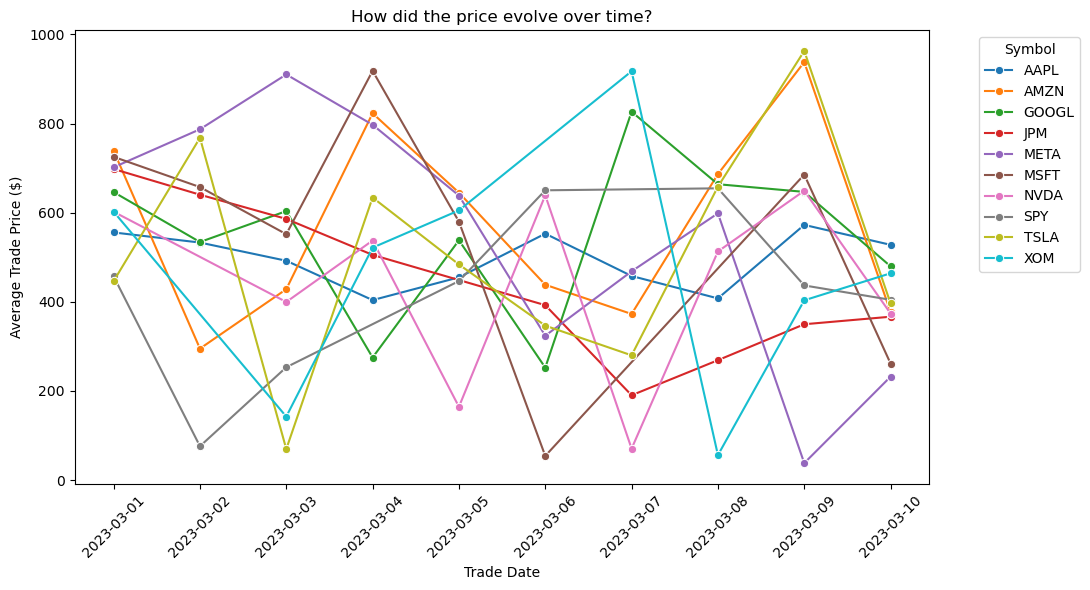

Insight: Average trade prices fluctuated significantly across symbols, with several sharp changes during the period.


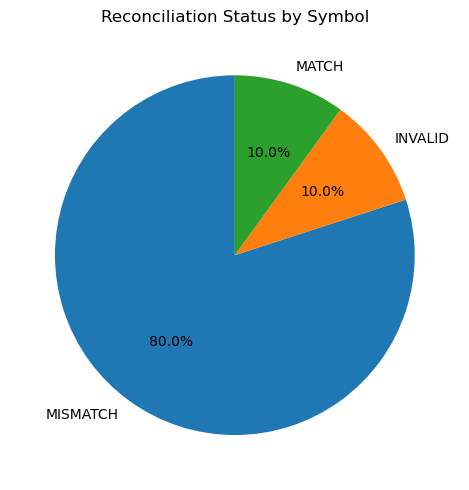

Insight: 10.0% of symbols reconciled correctly, while 80.0% showed mismatches and 10.0% had invalid data.


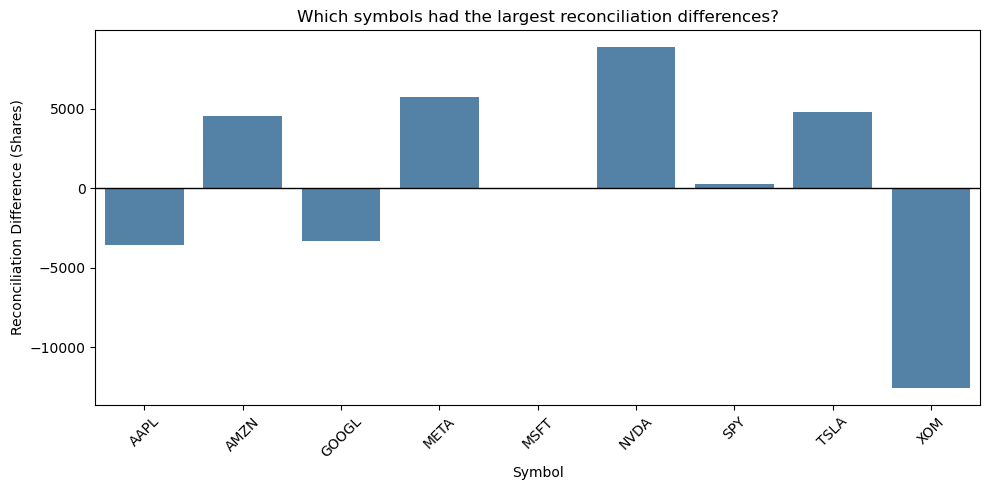

Insight: XOM had the largest absolute reconciliation difference.

All visualizations saved successfully.


In [ ]:
"""
Part 8: Data Visualization

Create the three required dashboard charts:
1) Trading volume by symbol
2) Price trends over time
3) Reconciliation success rate

Additional chart:
4) Reconciliation differences by symbol
"""

print("\nPART 8: DATA VISUALIZATION")
print("----------------------")

# Chart 1: Which symbols had the highest trading volume?
volume_data = symbol_report.sort_values(
    "total_quantity", ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=volume_data,
    x="symbol",
    y="total_quantity",
    color="steelblue"
)

plt.title("Which symbols had the highest trading volume?")
plt.xlabel("Symbol")
plt.ylabel("Total Trading Quantity (Shares)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("reports/trading_volume.png", dpi=300)
plt.show()

print(
    "Insight: AAPL had the highest trading volume, "
    "followed by GOOGL and META."
)

# Chart 2: How did the price evolve over time?
# Calculate daily average prices for each symbol
price_trend = (
    df_clean
    .groupby(["trade_date", "symbol"], as_index=False)["price"]
    .mean()
)

plt.figure(figsize=(11, 6))

# Assign consistent colors to symbols
symbols = sorted(df_clean["symbol"].unique())

colors = dict(
    zip(symbols, sns.color_palette("tab10", len(symbols)))
)

sns.lineplot(
    data=price_trend,
    x="trade_date",
    y="price",
    hue="symbol",
    hue_order=symbols,
    palette=colors,
    marker="o"
)

plt.title("How did the price evolve over time?")
plt.xlabel("Trade Date")
plt.ylabel("Average Trade Price ($)")
plt.xticks(rotation=45)
plt.legend(title="Symbol", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig("reports/price_trend.png", dpi=300, bbox_inches="tight")
plt.show()

print(
    "Insight: Average trade prices fluctuated significantly "
    "across symbols, with several sharp changes during the period."
)

# Chart 3: Reconciliation Status by Symbol
status_count = recon["status"].value_counts()

plt.figure(figsize=(7, 5))

plt.pie(
    status_count.values,
    labels=status_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Reconciliation Status by Symbol")
plt.tight_layout()
plt.savefig("reports/reconciliation_rate.png", dpi=300)
plt.show()

match_rate = (recon["status"] == "MATCH").mean() * 100
mismatch_rate = (recon["status"] == "MISMATCH").mean() * 100
invalid_rate = (recon["status"] == "INVALID").mean() * 100

print(
    f"Insight: {match_rate:.1f}% of symbols reconciled correctly, "
    f"while {mismatch_rate:.1f}% showed mismatches "
    f"and {invalid_rate:.1f}% had invalid data."
)

# Chart 4: Which symbols had the largest reconciliation differences?
# Exclude INVALID records with missing differences
recon_valid = recon[recon["status"] != "INVALID"]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=recon_valid,
    x="symbol",
    y="recon_diff",
    color="steelblue"
)

plt.axhline(0, color="black", linewidth=1)
plt.title("Which symbols had the largest reconciliation differences?")
plt.xlabel("Symbol")
plt.ylabel("Reconciliation Difference (Shares)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("reports/reconciliation_difference.png", dpi=300)
plt.show()

print("Insight: XOM had the largest absolute reconciliation difference.")

print("\nAll visualizations saved successfully.")